# Example 01: Peak factor models

Random vibration theory computes the peak of a motion as the product of a peak factor and the root-mean-square (RMS) of the motion. The peak factor depends on the duration and on the frequency content, and the models of it differ. This example computes the response spectrum of one Fourier amplitude spectrum with each of the peak calculators of pyRVT, and shows how much the choice changes the response.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pygmm import fourier_spectrum

import pyrvt

%matplotlib inline

## Fourier amplitude spectrum

The spectrum is the source-theory model of pyGMM for a $M_w$ 6.5 earthquake 20 km from the site in western North America. Any object with `freqs`, `fourier_amps` and `duration` can be used: `RvtMotion.from_fas` takes those and the peak calculator.

In [2]:
fas = fourier_spectrum.SourceTheoryModel(magnitude=6.5, distance=20.0, region="wna")
print(f"Duration: {fas.duration:.1f} s")

Duration: 6.1 s


## Response spectra with each peak calculator

The calculators are selected with an abbreviation: the initials of the authors and the last two digits of the year. `pyrvt.peak_calculators.get_peak_calculator` returns the calculator for an abbreviation, and `from_fas` accepts the abbreviation.

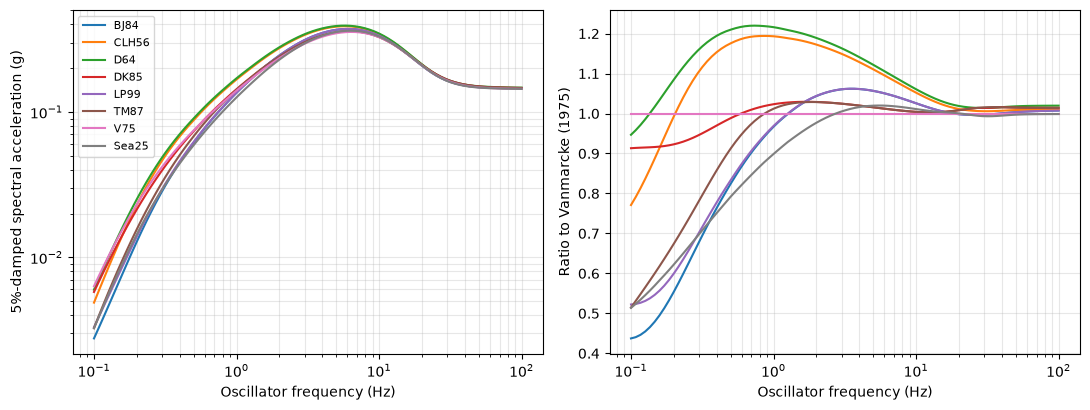

In [3]:
names = ["BJ84", "CLH56", "D64", "DK85", "LP99", "TM87", "V75", "Sea25"]
osc_freqs = np.geomspace(0.1, 100, num=91)
osc_damping = 0.05

motions = {
    name: pyrvt.motions.RvtMotion.from_fas(fas, peak_calculator=name) for name in names
}
spectra = {
    name: m.calc_osc_accels(osc_freqs, osc_damping) for name, m in motions.items()
}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True)
for name, sa in spectra.items():
    axes[0].plot(osc_freqs, sa, label=name)
    axes[1].plot(osc_freqs, sa / spectra["V75"], label=name)
axes[0].set(xscale="log", yscale="log", ylabel="5%-damped spectral acceleration (g)")
axes[1].set(xscale="log", ylabel="Ratio to Vanmarcke (1975)")
for ax in axes:
    ax.set_xlabel("Oscillator frequency (Hz)")
    ax.grid(True, which="both", alpha=0.3)
axes[0].legend(fontsize=8)
fig.tight_layout()

In [4]:
rows = {
    name: {"PGA (g)": m.pga, "PGV (cm/s)": m.pgv}
    | {
        f"SA({f} Hz) (g)": np.interp(f, osc_freqs, spectra[name])
        for f in (0.5, 5.0, 20.0)
    }
    for name, m in motions.items()
}
pd.DataFrame(rows).T.round(3)

,PGA (g),PGV (cm/s),SA(0.5 Hz) (g),SA(5.0 Hz) (g),SA(20.0 Hz) (g)
BJ84,0.145,13.223,0.061,0.368,0.208
CLH56,0.145,13.223,0.088,0.386,0.211
D64,0.146,13.486,0.090,0.390,0.213
DK85,0.145,13.486,0.074,0.353,0.210
LP99,0.145,13.223,0.062,0.368,0.208
TM87,0.145,13.648,0.068,0.353,0.210
V75,0.143,13.254,0.075,0.348,0.209
Sea25,0.143,12.315,0.059,0.355,0.209


## Peak calculators with parameters

The calculators of Boore and Thompson (2012, 2015) and Wang and Rathje (2018) depend on the region, magnitude (`mag`) and distance (`dist`) of the earthquake, which are passed in `calc_kwds`.

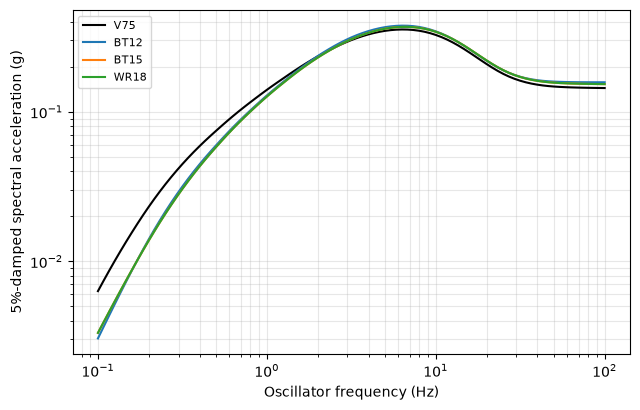

In [5]:
calc_kwds = {"region": "wna", "mag": 6.5, "dist": 20.0}
extra = {}
for name in ["BT12", "BT15", "WR18"]:
    m = pyrvt.motions.RvtMotion.from_fas(fas, peak_calculator=name, calc_kwds=calc_kwds)
    extra[name] = m.calc_osc_accels(osc_freqs, osc_damping)

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.plot(osc_freqs, spectra["V75"], "k", label="V75")
for name, sa in extra.items():
    ax.plot(osc_freqs, sa, label=name)
ax.set(
    xscale="log",
    yscale="log",
    xlabel="Oscillator frequency (Hz)",
    ylabel="5%-damped spectral acceleration (g)",
)
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()

### Observations

- **The calculators agree within a few percent at high frequencies** (from 20 Hz up they are within 2% of Vanmarcke (1975)) and for the PGA, which is 0.143 to 0.146 g.
- **They differ at low oscillator frequencies**, where the duration of the oscillator response is long compared with the duration of the motion: at 0.5 Hz the spectral acceleration ranges from 0.059 g (Seifried et al., 2025) to 0.090 g (Davenport, 1964), and at 0.1 Hz Boore and Joyner (1984) is 44% of Vanmarcke (1975) while Davenport (1964) and Cartwright and Longuet-Higgins (1956) are 77% to 95% of it.
- **Near 1 Hz** Davenport (1964) and Cartwright and Longuet-Higgins (1956) are about 20% above Vanmarcke (1975), and Seifried et al. (2025) is 10% below it; at 5 Hz the largest difference is 12% (Davenport, 1964).
- **The calculators of Boore and Thompson (2012, 2015) and Wang and Rathje (2018)**, which take the region, magnitude and distance, give nearly the same spectrum, which is about half of Vanmarcke (1975) at 0.1 Hz and 5% to 9% above it from 5 Hz up.